# **KẾT NỐI GOOGLE DRIVE**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# **Exploratory Data Analysis (EDA)**

**Kiểm tra số lượng các cột dữ liệu**

In [ ]:
import pandas as pd, numpy as np

df = pd.read_csv("/content/drive/MyDrive/IS6002/merged_dataset/combined_labeled_features_clean.csv", low_memory=False)
display(df.head())

,contract_id,PUSH1,MSTORE,CALLDATASIZE,LT,PUSH2,JUMPI,CALLDATALOAD,PUSH29,SWAP1,...,UNKNOWN_0xB5,UNKNOWN_0xD1,UNKNOWN_0xEC,UNKNOWN_0xA9,UNKNOWN_0xAC,UNKNOWN_0x2D,UNKNOWN_0xCA,label,vulnerability_type,source_dataset
0,C000001,470,109,22.0,13.0,170.0,89.0,32.0,1.0,258.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Vulnerable,Overflow-Underflow,SolidiFI
1,C000002,366,83,13.0,12.0,142.0,67.0,16.0,1.0,199.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Vulnerable,Overflow-Underflow,SolidiFI
2,C000003,1081,218,45.0,62.0,455.0,243.0,64.0,0.0,571.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Vulnerable,Overflow-Underflow,SolidiFI
3,C000004,1164,251,52.0,21.0,479.0,250.0,67.0,7.0,611.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Vulnerable,Overflow-Underflow,SolidiFI
4,C000005,556,131,22.0,34.0,193.0,96.0,34.0,0.0,279.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Vulnerable,Overflow-Underflow,SolidiFI


In [ ]:
print("Số lượng cột:", len(df.columns))

print("\nDanh sách tên cột:")
for i, col in enumerate(df.columns):
    print(f"{i}: {col}")

Số lượng cột: 260

Danh sách tên cột:
0: contract_id
1: PUSH1
2: MSTORE
3: CALLDATASIZE
4: LT
5: PUSH2
6: JUMPI
7: CALLDATALOAD
8: PUSH29
9: SWAP1
10: DIV
11: PUSH4
12: AND
13: DUP1
14: EQ
15: JUMPDEST
16: REVERT
17: CALLVALUE
18: ISZERO
19: POP
20: JUMP
21: MLOAD
22: ADD
23: DUP3
24: DUP2
25: SUB
26: DUP4
27: SWAP2
28: DUP5
29: EXP
30: NOT
31: SWAP3
32: RETURN
33: PUSH20
34: STOP
35: SLOAD
36: MUL
37: KECCAK256
38: GT
39: CALLER
40: DUP6
41: SSTORE
42: PUSH32
43: LOG3
44: DUP7
45: DUP8
46: SWAP4
47: TIMESTAMP
48: DUP9
49: CALL
50: RETURNDATASIZE
51: RETURNDATACOPY
52: CALLDATACOPY
53: SWAP5
54: INVALID
55: OR
56: LOG1
57: SHR
58: PUSH5
59: ADDRESS
60: SHL
61: SWAP6
62: EXTCODESIZE
63: GAS
64: DUP10
65: LOG2
66: DUP11
67: PUSH8
68: SELFBALANCE
69: STATICCALL
70: NUMBER
71: MOD
72: BLOCKHASH
73: SELFDESTRUCT
74: SWAP8
75: CODECOPY
76: PUSH31
77: PUSH16
78: PUSH15
79: PUSH21
80: PUSH6
81: PUSH9
82: DUP13
83: DUP12
84: SWAP12
85: DUP14
86: DUP15
87: SWAP7
88: PUSH3
89: MSTORE8
90: SWAP11


In [ ]:
print("Kích thước dataset:", df.shape)

print("\nSố contract:", len(df))
print("Số contract_id duy nhất:", df["contract_id"].nunique())

print("\nPhân bố label:")
print(df["label"].value_counts())

print("\nPhân bố source_dataset:")
print(df["source_dataset"].value_counts())


Kích thước dataset: (39905, 260)

Số contract: 39905
Số contract_id duy nhất: 39905

Phân bố label:
label
Vulnerable        28048
Non-vulnerable    11857
Name: count, dtype: int64

Phân bố source_dataset:
source_dataset
Slither-Wild         39414
SolidiFI               350
SmartBugs-Curated      141
Name: count, dtype: int64


**Phân bổ nhãn**

label
Vulnerable        28048
Non-vulnerable    11857
Name: count, dtype: int64

Tỷ lệ phần trăm:
label
Vulnerable        70.29
Non-vulnerable    29.71
Name: proportion, dtype: float64


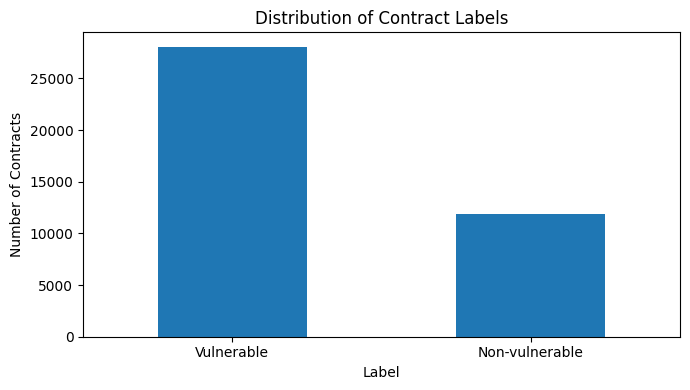

In [ ]:
import matplotlib.pyplot as plt

label_counts = df["label"].value_counts()

print(label_counts)
print("\nTỷ lệ phần trăm:")
print((df["label"].value_counts(normalize=True) * 100).round(2))

label_counts.plot(
    kind="bar",
    figsize=(7, 4),
    rot=0
)

plt.title("Distribution of Contract Labels")
plt.xlabel("Label")
plt.ylabel("Number of Contracts")
plt.tight_layout()
plt.show()


**Loại bỏ 2 cột "vulnerability_type" và "source_dataset"**

In [ ]:
df = df.drop(columns=["vulnerability_type", "source_dataset"])

df.head()

,contract_id,PUSH1,MSTORE,CALLDATASIZE,LT,PUSH2,JUMPI,CALLDATALOAD,PUSH29,SWAP1,...,UNKNOWN_0xBE,UNKNOWN_0x28,UNKNOWN_0xB5,UNKNOWN_0xD1,UNKNOWN_0xEC,UNKNOWN_0xA9,UNKNOWN_0xAC,UNKNOWN_0x2D,UNKNOWN_0xCA,label
0,C000001,470,109,22.0,13.0,170.0,89.0,32.0,1.0,258.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Vulnerable
1,C000002,366,83,13.0,12.0,142.0,67.0,16.0,1.0,199.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Vulnerable
2,C000003,1081,218,45.0,62.0,455.0,243.0,64.0,0.0,571.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Vulnerable
3,C000004,1164,251,52.0,21.0,479.0,250.0,67.0,7.0,611.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Vulnerable
4,C000005,556,131,22.0,34.0,193.0,96.0,34.0,0.0,279.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Vulnerable


**Kiểm tra còn ô nào không có giá trị (là NaN/NULL không)**

In [ ]:
print("Tổng NaN:", df.isna().sum().sum())

na_cols = df.isna().sum()
print(na_cols[na_cols > 0])

assert not df.isna().any().any(), "Vẫn còn NaN!"
print("Không có NaN/Null. Shape:", df.shape)

Tổng NaN: 0
Series([], dtype: int64)
Không có NaN/Null. Shape: (39905, 258)


In [ ]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
contract_id,39905,39905,C035665,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PUSH1,39905.0,NaN,NaN,NaN,842.178699,940.470009,2.0,342.0,534.0,1000.0,18975.0
MSTORE,39905.0,NaN,NaN,NaN,201.968826,222.356865,1.0,84.0,131.0,236.0,3905.0
CALLDATASIZE,39905.0,NaN,NaN,NaN,20.463175,23.534432,0.0,6.0,15.0,25.0,460.0
LT,39905.0,NaN,NaN,NaN,23.874276,36.37846,0.0,9.0,13.0,24.0,1066.0
...,...,...,...,...,...,...,...,...,...,...,...
UNKNOWN_0xA9,39905.0,NaN,NaN,NaN,0.002757,0.220475,0.0,0.0,0.0,0.0,43.0
UNKNOWN_0xAC,39905.0,NaN,NaN,NaN,0.003659,0.398016,0.0,0.0,0.0,0.0,79.0
UNKNOWN_0x2D,39905.0,NaN,NaN,NaN,0.003258,0.0828,0.0,0.0,0.0,0.0,8.0
UNKNOWN_0xCA,39905.0,NaN,NaN,NaN,0.001353,0.039394,0.0,0.0,0.0,0.0,2.0


**Số lượng cột theo từng kiểu dữ liệu**

In [ ]:
print("Số lượng cột theo kiểu dữ liệu:")
print(df.dtypes.value_counts())

Số lượng cột theo kiểu dữ liệu:
float64    254
object       2
int64        2
Name: count, dtype: int64


**Kiểm tra sự phân phối của các cột Opcode**

Số cột opcode: 256
Số giá trị thiếu trong opcode: 0

20 opcode xuất hiện nhiều nhất:


,total_count
PUSH1,33607141.0
SWAP1,18396075.0
POP,16793736.0
DUP1,16326735.0
PUSH2,13278148.0
DUP2,12945179.0
ADD,12264083.0
JUMPDEST,10689861.0
AND,10442519.0
ISZERO,8474033.0


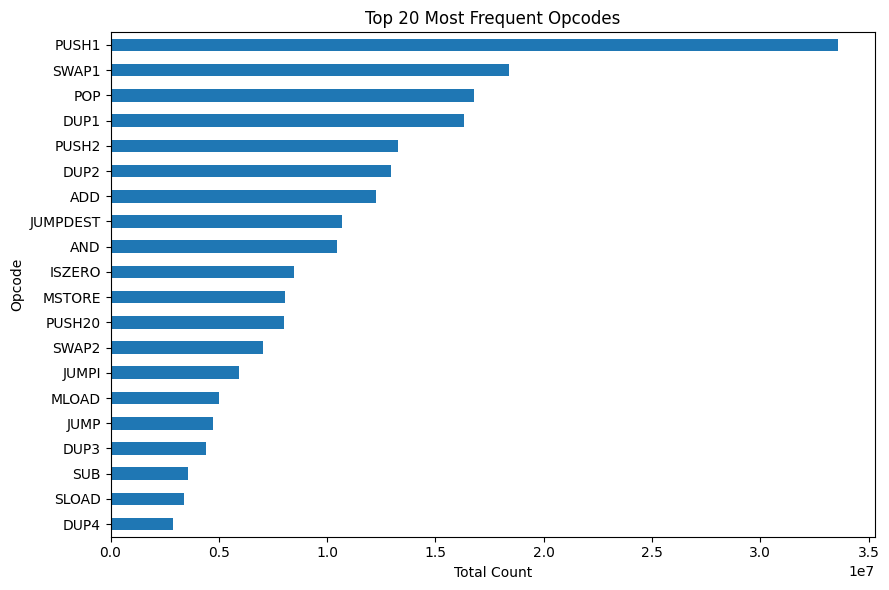

In [ ]:
metadata_cols = [
    "contract_id",
    "label",
    "vulnerability_type",
    "source_dataset"
]

opcode_cols = [
    col for col in df.columns
    if col not in metadata_cols
]

X_eda = df[opcode_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

print("Số cột opcode:", len(opcode_cols))
print("Số giá trị thiếu trong opcode:",
      X_eda.isnull().sum().sum())

opcode_totals = X_eda.sum().sort_values(ascending=False)

print("\n20 opcode xuất hiện nhiều nhất:")
display(opcode_totals.head(20).to_frame("total_count"))

opcode_totals.head(20).sort_values().plot(
    kind="barh",
    figsize=(9, 6)
)

plt.title("Top 20 Most Frequent Opcodes")
plt.xlabel("Total Count")
plt.ylabel("Opcode")
plt.tight_layout()
plt.show()


,count,mean,std,min,25%,50%,75%,max
Label,,,,,,,,
Non-vulnerable,11857.0,3873.38,3033.61,6.0,2010.00,3325.0,4332.00,31638.0
Vulnerable,28048.0,6976.52,7679.08,21.0,2849.75,4633.0,8444.25,148591.0


<Figure size 900x500 with 0 Axes>

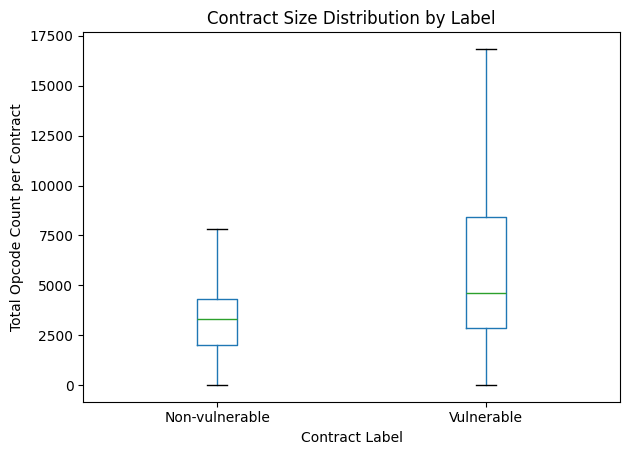

In [ ]:
contract_size = X_eda.sum(axis=1)

plot_df = pd.DataFrame({
    "Contract Size": contract_size,
    "Label": df["label"].astype(str).str.strip()
})

display(
    plot_df.groupby("Label")["Contract Size"]
    .describe()
    .round(2)
)

plt.figure(figsize=(9, 5))

plot_df.boxplot(
    column="Contract Size",
    by="Label",
    grid=False,
    showfliers=False
)

plt.title("Contract Size Distribution by Label")
plt.suptitle("")
plt.xlabel("Contract Label")
plt.ylabel("Total Opcode Count per Contract")
plt.tight_layout()
plt.show()


# **PREPROCESSING**

In [ ]:
df.head()

,contract_id,PUSH1,MSTORE,CALLDATASIZE,LT,PUSH2,JUMPI,CALLDATALOAD,PUSH29,SWAP1,...,UNKNOWN_0xBE,UNKNOWN_0x28,UNKNOWN_0xB5,UNKNOWN_0xD1,UNKNOWN_0xEC,UNKNOWN_0xA9,UNKNOWN_0xAC,UNKNOWN_0x2D,UNKNOWN_0xCA,label
0,C000001,470,109,22.0,13.0,170.0,89.0,32.0,1.0,258.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Vulnerable
1,C000002,366,83,13.0,12.0,142.0,67.0,16.0,1.0,199.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Vulnerable
2,C000003,1081,218,45.0,62.0,455.0,243.0,64.0,0.0,571.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Vulnerable
3,C000004,1164,251,52.0,21.0,479.0,250.0,67.0,7.0,611.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Vulnerable
4,C000005,556,131,22.0,34.0,193.0,96.0,34.0,0.0,279.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Vulnerable


In [ ]:
y = df["label"].copy()

contract_ids = df["contract_id"].copy()

opcode_cols = [
    col for col in df.columns
    if col not in ["contract_id", "label"]
]

X = df[opcode_cols].copy()

print("Số contracts:", len(df))
print("Số opcode features:", len(opcode_cols))
print("Kích thước X:", X.shape)
print("\nPhân bố nhãn:")
print(y.value_counts())

Số contracts: 39905
Số opcode features: 256
Kích thước X: (39905, 256)

Phân bố nhãn:
label
Vulnerable        28048
Non-vulnerable    11857
Name: count, dtype: int64


In [ ]:
print("Các kiểu dữ liệu trong X:")
print(X.dtypes.value_counts())

print("\nSố giá trị thiếu:", X.isna().sum().sum())
print("Số giá trị vô cực:", np.isinf(X.select_dtypes(include="number")).sum().sum())

Các kiểu dữ liệu trong X:
float64    254
int64        2
Name: count, dtype: int64

Số giá trị thiếu: 0
Số giá trị vô cực: 0


In [ ]:
unique_counts = X.nunique()

constant_cols = unique_counts[unique_counts <= 1].index.tolist()

print("Số opcode features ban đầu:", X.shape[1])
print("Số constant features:", len(constant_cols))
print("\nDanh sách constant features:")
print(constant_cols)

Số opcode features ban đầu: 256
Số constant features: 0

Danh sách constant features:
[]


**Kiểm tra phân bố và độ lệch của dữ liệu X**

In [ ]:
display(X.describe().T[["mean", "std", "min", "50%", "max"]].round(2))

,mean,std,min,50%,max
PUSH1,842.18,940.47,2.0,534.0,18975.0
MSTORE,201.97,222.36,1.0,131.0,3905.0
CALLDATASIZE,20.46,23.53,0.0,15.0,460.0
LT,23.87,36.38,0.0,13.0,1066.0
PUSH2,332.74,394.52,0.0,202.0,8955.0
...,...,...,...,...,...
UNKNOWN_0xEC,0.02,4.11,0.0,0.0,820.0
UNKNOWN_0xA9,0.00,0.22,0.0,0.0,43.0
UNKNOWN_0xAC,0.00,0.40,0.0,0.0,79.0
UNKNOWN_0x2D,0.00,0.08,0.0,0.0,8.0


# K-MEANS A — CHIA TRAIN/TEST

Quy trình độc lập. TF-IDF và K-Means chỉ được fit trên train; test chỉ dùng `transform` và `predict`.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    balanced_accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, silhouette_score
)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train_raw.shape, "Test:", X_test_raw.shape)
print("Train label distribution:\n", y_train.value_counts())
print("Test label distribution:\n", y_test.value_counts())


Train: (31924, 256) Test: (7981, 256)
Train label distribution:
 label
Vulnerable        22438
Non-vulnerable     9486
Name: count, dtype: int64
Test label distribution:
 label
Vulnerable        5610
Non-vulnerable    2371
Name: count, dtype: int64


In [ ]:
tfidf_train = TfidfTransformer(norm="l2", use_idf=True, sublinear_tf=True)
X_train_tfidf = tfidf_train.fit_transform(X_train_raw)
X_test_tfidf = tfidf_train.transform(X_test_raw)

print("X_train_tfidf:", X_train_tfidf.shape)
print("X_test_tfidf:", X_test_tfidf.shape)


X_train_tfidf: (31924, 256)
X_test_tfidf: (7981, 256)


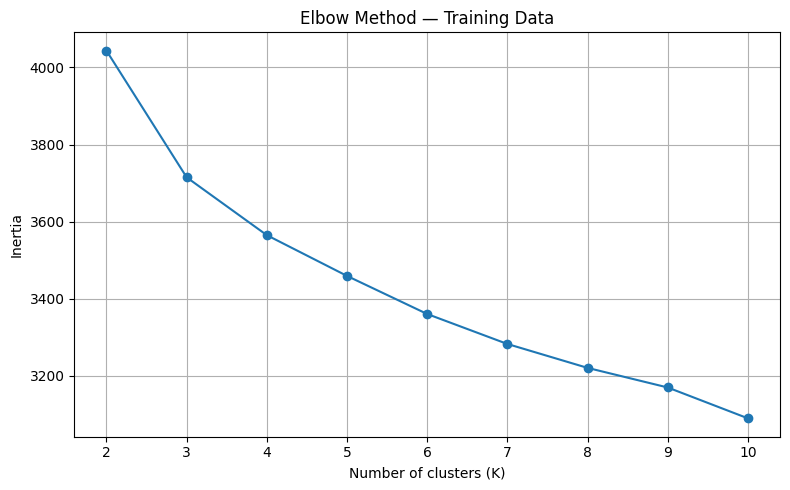

In [ ]:
k_values_train = range(2, 11)
inertias_train = []
for k in k_values_train:
    model_train_k = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=300)
    model_train_k.fit(X_train_tfidf)
    inertias_train.append(model_train_k.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values_train), inertias_train, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method — Training Data")
plt.xticks(list(k_values_train))
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
kmeans_train = KMeans(n_clusters=5, random_state=42, n_init=200, max_iter=100)
train_clusters = kmeans_train.fit_predict(X_train_tfidf)
test_clusters = kmeans_train.predict(X_test_tfidf)

print("Train samples:", len(train_clusters))
print("Test samples:", len(test_clusters))
print("Train inertia:", kmeans_train.inertia_)
print("Train silhouette (sample):", round(silhouette_score(
    X_train_tfidf, train_clusters,
    sample_size=min(5000, X_train_tfidf.shape[0]), random_state=42
), 4))


Train samples: 31924
Test samples: 7981
Train inertia: 3458.122189415909
Train silhouette (sample): 0.1217


In [ ]:
def make_cluster_distribution(clusters, labels):
    temp = pd.DataFrame({
        "Cluster": np.asarray(clusters),
        "Label": np.asarray(labels)
    })
    counts = pd.crosstab(temp["Cluster"], temp["Label"])
    for label in ["Vulnerable", "Non-vulnerable"]:
        if label not in counts.columns:
            counts[label] = 0
    counts = counts[["Vulnerable", "Non-vulnerable"]]
    result = pd.DataFrame(index=counts.index)
    result.index.name = "Cluster"
    result["Harmful Data Points"] = counts["Vulnerable"]
    result["Harmful Data Percentage"] = (
        counts["Vulnerable"] / max(counts["Vulnerable"].sum(), 1) * 100
    ).round(3)
    result["Non-harmful Data Points"] = counts["Non-vulnerable"]
    result["Non-harmful Data Percentage"] = (
        counts["Non-vulnerable"] / max(counts["Non-vulnerable"].sum(), 1) * 100
    ).round(3)
    result["Total in Cluster"] = counts.sum(axis=1)
    result["Vulnerable within Cluster (%)"] = (
        counts["Vulnerable"] / result["Total in Cluster"] * 100
    ).round(2)
    return result

print("TRAIN CLUSTER DISTRIBUTION")
display(make_cluster_distribution(train_clusters, y_train))
print("TEST CLUSTER DISTRIBUTION")
display(make_cluster_distribution(test_clusters, y_test))


TRAIN CLUSTER DISTRIBUTION


,Harmful Data Points,Harmful Data Percentage,Non-harmful Data Points,Non-harmful Data Percentage,Total in Cluster,Vulnerable within Cluster (%)
Cluster,,,,,,
0,2714,12.096,33,0.348,2747,98.80
1,4738,21.116,8709,91.809,13447,35.23
2,1121,4.996,118,1.244,1239,90.48
3,4415,19.676,77,0.812,4492,98.29
4,9450,42.116,549,5.787,9999,94.51


TEST CLUSTER DISTRIBUTION


,Harmful Data Points,Harmful Data Percentage,Non-harmful Data Points,Non-harmful Data Percentage,Total in Cluster,Vulnerable within Cluster (%)
Cluster,,,,,,
0,627,11.176,11,0.464,638,98.28
1,1173,20.909,2190,92.366,3363,34.88
2,277,4.938,16,0.675,293,94.54
3,1103,19.661,11,0.464,1114,99.01
4,2430,43.316,143,6.031,2573,94.44


In [ ]:
train_cluster_labels = pd.DataFrame({
    "Cluster": train_clusters,
    "Label": np.asarray(y_train)
})
cluster_label_map_train = (
    train_cluster_labels.groupby(["Cluster", "Label"])
    .size().unstack(fill_value=0).idxmax(axis=1)
)
print("Cluster label map learned from train:")
display(cluster_label_map_train)


Cluster label map learned from train:


,0
Cluster,
0,Vulnerable
1,Non-vulnerable
2,Vulnerable
3,Vulnerable
4,Vulnerable


In [ ]:
def calculate_metrics(y_true, y_pred):
    return {
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0)
    }

y_train_pred = pd.Series(train_clusters).map(cluster_label_map_train)
y_test_pred = pd.Series(test_clusters).map(cluster_label_map_train)

metrics_table = pd.DataFrame({
    "Training Data (in-sample)": calculate_metrics(y_train, y_train_pred),
    "Test Data": calculate_metrics(y_test, y_test_pred)
})
display(metrics_table.round(6))


,Training Data (in-sample),Test Data
Balanced Accuracy,0.853465,0.857285
Macro Precision,0.802801,0.806005
Macro Recall,0.853465,0.857285
Macro F1,0.812363,0.815741


In [ ]:
test_cluster_mapping = pd.DataFrame({
    "Cluster": test_clusters,
    "True Label": np.asarray(y_test),
    "Predicted Label": y_test_pred
})

test_cluster_mapping_table = (
    test_cluster_mapping
    .groupby(["Cluster", "Predicted Label", "True Label"])
    .size()
    .unstack(fill_value=0)
)

print("TEST CLUSTER MAPPING AND TRUE LABEL COUNTS")
display(test_cluster_mapping_table)


TEST CLUSTER MAPPING AND TRUE LABEL COUNTS


,True Label,Non-vulnerable,Vulnerable
Cluster,Predicted Label,,
0,Vulnerable,11,627
1,Non-vulnerable,2190,1173
2,Vulnerable,16,277
3,Vulnerable,11,1103
4,Vulnerable,143,2430


In [ ]:
print("TEST EVALUATION METRICS")
display(
    pd.DataFrame(
        calculate_metrics(y_test, y_test_pred),
        index=["Test Data"]
    ).T.round(6)
)


TEST EVALUATION METRICS


,Test Data
Balanced Accuracy,0.857285
Macro Precision,0.806005
Macro Recall,0.857285
Macro F1,0.815741


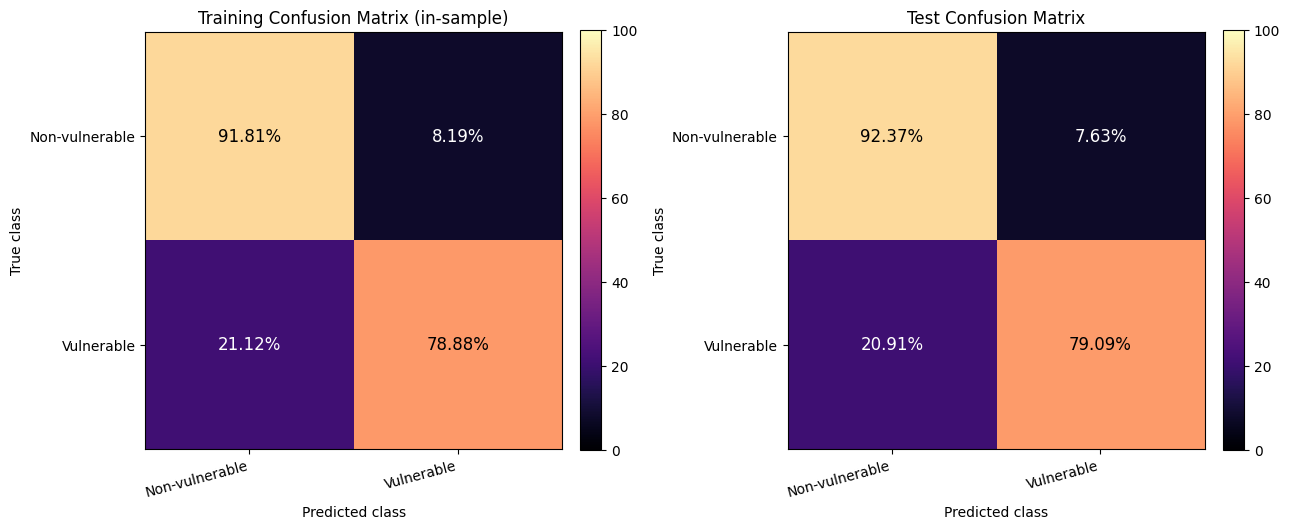

Train confusion matrix (%):
 [[91.81  8.19]
 [21.12 78.88]]

Test confusion matrix (%):
 [[92.37  7.63]
 [20.91 79.09]]


In [ ]:
class_names = ["Non-vulnerable", "Vulnerable"]
cm_train = confusion_matrix(y_train, y_train_pred, labels=class_names, normalize="true") * 100
cm_test = confusion_matrix(y_test, y_test_pred, labels=class_names, normalize="true") * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, cm, title in [
    (axes[0], cm_train, "Training Confusion Matrix (in-sample)"),
    (axes[1], cm_test, "Test Confusion Matrix")
]:
    im = ax.imshow(cm, cmap="magma", vmin=0, vmax=100)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:.2f}%", ha="center", va="center",
                    color="white" if cm[i, j] < 50 else "black", fontsize=12)
    ax.set_title(title)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(class_names, rotation=15, ha="right")
    ax.set_yticklabels(class_names)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()
print("Train confusion matrix (%):\n", np.round(cm_train, 2))
print("\nTest confusion matrix (%):\n", np.round(cm_test, 2))


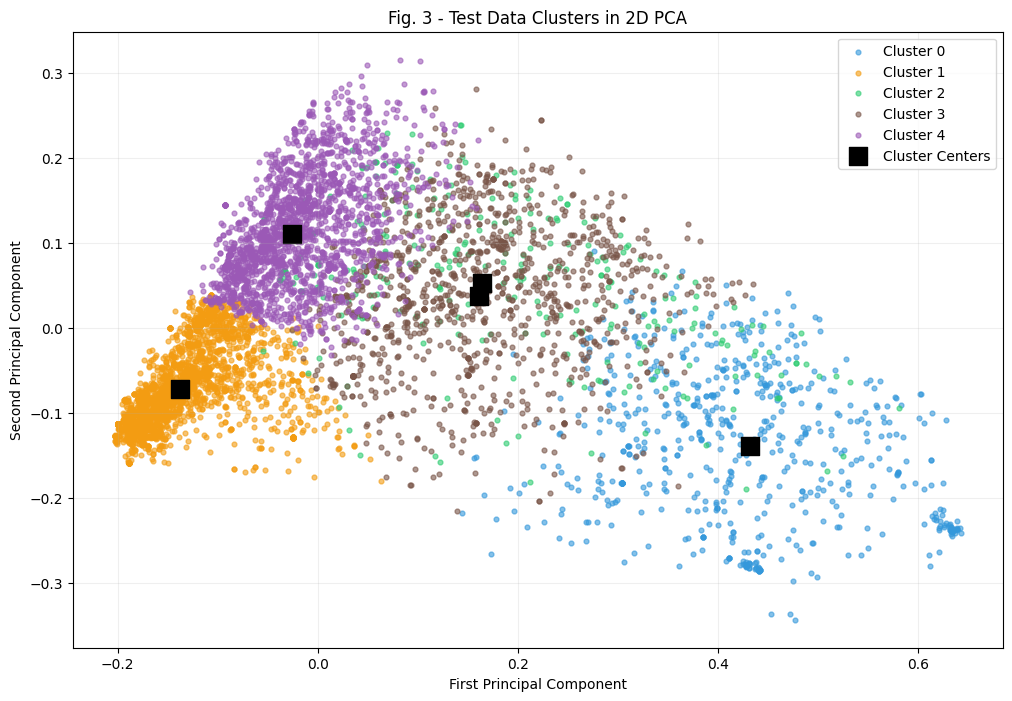

In [ ]:

from sklearn.decomposition import PCA


pca_2d = PCA(n_components=2, random_state=42)

X_train_2d = pca_2d.fit_transform(X_train_tfidf.toarray())
X_test_2d = pca_2d.transform(X_test_tfidf.toarray())

centers_2d = pca_2d.transform(kmeans_train.cluster_centers_)

cluster_colors = [
    "#3498DB", "#F39C12", "#2ECC71", "#795548", "#9B59B6"
]

plt.figure(figsize=(12, 8))

for cluster_id in range(5):
    mask = test_clusters == cluster_id
    plt.scatter(
        X_test_2d[mask, 0],
        X_test_2d[mask, 1],
        c=cluster_colors[cluster_id],
        s=12,
        alpha=0.6,
        label=f"Cluster {cluster_id}"
    )

plt.scatter(
    centers_2d[:, 0],
    centers_2d[:, 1],
    c="black",
    marker="s",
    s=150,
    label="Cluster Centers"
)

plt.title("Fig. 3 - Test Data Clusters in 2D PCA")
plt.xlabel("First Principal Component")
plt.ylabel("Second Principal Component")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


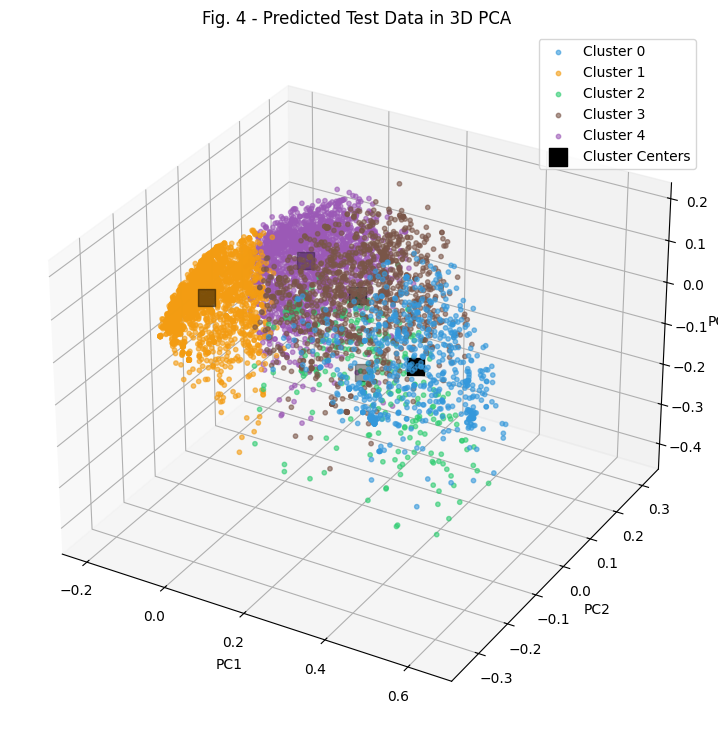

In [ ]:

from mpl_toolkits.mplot3d import Axes3D

pca_3d = PCA(n_components=3, random_state=42)

X_train_3d = pca_3d.fit_transform(X_train_tfidf.toarray())
X_test_3d = pca_3d.transform(X_test_tfidf.toarray())

centers_3d = pca_3d.transform(kmeans_train.cluster_centers_)

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection="3d")

for cluster_id in range(5):
    mask = test_clusters == cluster_id
    ax.scatter(
        X_test_3d[mask, 0],
        X_test_3d[mask, 1],
        X_test_3d[mask, 2],
        c=cluster_colors[cluster_id],
        s=10,
        alpha=0.6,
        label=f"Cluster {cluster_id}"
    )

ax.scatter(
    centers_3d[:, 0],
    centers_3d[:, 1],
    centers_3d[:, 2],
    c="black",
    marker="s",
    s=150,
    label="Cluster Centers"
)

ax.set_title("Fig. 4 - Predicted Test Data in 3D PCA")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.legend()
plt.show()
